# Visual odometry I: camera motion from two frames

**Visual odometry (VO)** estimates how a camera moves by looking at consecutive images. It is
the "dead reckoning" of a robot with a camera: no map, no loop closure, just one relative
motion after the other, integrated into a trajectory.

This notebook builds the two basic VO measurements from scratch on real Kinect data
(TUM RGB-D *fr1/xyz*) and checks every number against motion-capture ground truth:

1. **Monocular 2D-2D**: feature matches -> essential matrix -> rotation + translation
   *direction* (the scale is unobservable from one camera).
2. **RGB-D 3D-2D**: back-project keypoints with the depth image -> **PnP** -> metric pose.

**What you'll learn**
- why fr1 images must be undistorted (and how to do it on keypoints, not images),
- ORB vs SIFT features and Lowe's ratio test,
- the epipolar constraint, the 5-point essential-matrix solver with RANSAC / MAGSAC++,
  `recoverPose`'s cheirality check, and why monocular translation has no scale,
- PnP with RANSAC + Levenberg-Marquardt refinement on depth-derived 3D points,
- how much *baseline* each method needs,
- how to chain relative poses into a trajectory and evaluate it with **ATE** / **RPE**
  (cross-checked against the `evo` package).

**Prerequisites:** pinhole camera model and RANSAC (project 01), epipolar geometry
(project 09). Data: `make data-12_visual_odometry` (TUM fr1/xyz + fr1/desk, ~0.8 GB).
Everything runs on the CPU (OpenCV + NumPy) in a few minutes.

## Setup

The VO building blocks (feature front end, essential matrix, PnP, triangulation, the full
pipelines and the metrics) live in `projects/12_visual_odometry/scripts/vo.py` so that the
notebooks, the command-line runner and the unit tests share one implementation. The
notebook calls them step by step and shows what happens inside.

In [1]:
# --- Setup: imports, seeding, repository paths and plot style ---
# vo.py (plain OpenCV + NumPy, CPU only) sits in the project's scripts/ folder; we add that
# folder to sys.path so it can be imported like a module.
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cvlab import device, io, tum, viz
from cvlab.geometry import (
    angle_between_deg,
    essential_from_Rt,
    fundamental_from_essential,
    invert_T,
    rotation_error_deg,
    unproject,
)

PROJECT = "12_visual_odometry"
sys.path.insert(0, str(io.project_dir(PROJECT) / "scripts"))
import vo  # noqa: E402

dev = device.setup(seed=0)  # seeds the RNGs and prints the software / hardware summary
viz.set_style()
ROOT = io.repo_root()
XYZ = io.data_dir("tum", "fr1_xyz", "rgbd_dataset_freiburg1_xyz")
RUNS = io.runs_dir(PROJECT, create=True)  # estimated trajectories (gitignored)
RESULTS = io.project_dir(PROJECT) / "results"  # small metric files (committed)
RESULTS.mkdir(exist_ok=True)
print("sequence:", XYZ.relative_to(ROOT), "| found:", XYZ.exists())
print("OpenCV", cv2.__version__, "| CPU threads used by OpenCV:", cv2.getNumThreads())

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
sequence: data/tum/fr1_xyz/rgbd_dataset_freiburg1_xyz | found: True
OpenCV 5.0.0 | CPU threads used by OpenCV: 24


## 1. The data: TUM RGB-D fr1/xyz

A hand-held Microsoft Kinect records **RGB** (640x480, ~30 Hz) and **depth** (16-bit PNG,
`z [m] = value / 5000`, 0 = no measurement). The depth is already *registered* to the RGB
camera, i.e. depth pixel $(u, v)$ belongs to RGB pixel $(u, v)$. A motion-capture system
provides the ground-truth pose of the RGB camera at 100 Hz as camera-to-world transforms
$T_{wc}$ (OpenCV axes: x right, y down, z forward).

RGB, depth and ground truth have independent timestamps, so frames are **associated** by
nearest timestamp ($|\Delta t| < 20$ ms), the same greedy one-to-one matching as TUM's
`associate.py`. In fr1/xyz the camera translates along its x, y and z axes over a
textured desk - the easy case for VO.

The RGB camera follows the pinhole model with intrinsics $K$:
$$u = f_x \frac{X}{Z} + c_x, \qquad v = f_y \frac{Y}{Z} + c_y .$$

790 associated frames over 26.6 s (29.7 Hz)
GT path length 8.01 m, mean speed 0.30 m/s
K =
 [[517.3   0.  318.6]
 [  0.  516.5 255.3]
 [  0.    0.    1. ]]
distortion (k1, k2, p1, p2, k3) = [ 0.2624 -0.9531 -0.0054  0.0026  1.1633]


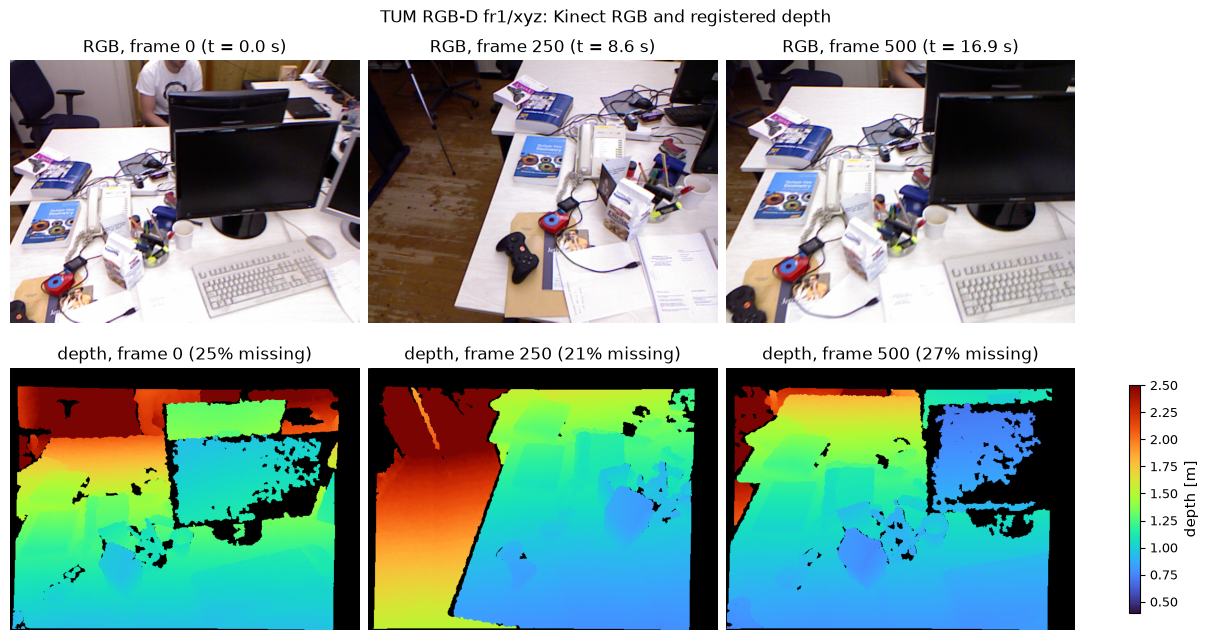

In [2]:
# --- Load fr1/xyz and look at a few RGB and depth frames ---
# load_sequence associates RGB, depth and ground truth by timestamp and returns the
# calibrated fr1 intrinsics K and the (k1, k2, p1, p2, k3) distortion of the RGB camera.
seq = tum.load_sequence(XYZ)
K, dist = seq.camera.K, seq.dist
duration = seq.timestamps[-1] - seq.timestamps[0]
gt_xyz = seq.gt_poses[:, :3, 3]  # camera centres in the mocap world frame [m]
path_len = np.linalg.norm(np.diff(gt_xyz, axis=0), axis=1).sum()
print(f"{len(seq)} associated frames over {duration:.1f} s ({(len(seq) - 1) / duration:.1f} Hz)")
print(f"GT path length {path_len:.2f} m, mean speed {path_len / duration:.2f} m/s")
print("K =\n", K.round(1))
print("distortion (k1, k2, p1, p2, k3) =", dist)

depth_cmap = plt.get_cmap("turbo").copy()
depth_cmap.set_bad("black")  # missing depth (0) is shown in black
idx = [0, 250, 500]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for col, i in enumerate(idx):
    axes[0, col].imshow(seq.rgb(i))
    axes[0, col].set_title(f"RGB, frame {i} (t = {seq.timestamps[i] - seq.timestamps[0]:.1f} s)")
    d = seq.depth(i)
    im = axes[1, col].imshow(np.where(d > 0, d, np.nan), cmap=depth_cmap, vmin=0.4, vmax=2.5)
    axes[1, col].set_title(f"depth, frame {i} ({(d == 0).mean():.0%} missing)")
for ax in axes.flat:
    ax.axis("off")
fig.colorbar(im, ax=axes[1, :], shrink=0.8, label="depth [m]")
fig.suptitle("TUM RGB-D fr1/xyz: Kinect RGB and registered depth")
viz.savefig(fig, PROJECT, "dataset_frames")
plt.show()

## 2. Lens distortion: undistort the keypoints, not the image

Only the *fr3* sequences of TUM were recorded with undistorted images; **fr1 RGB is raw**.
The Brown-Conrady model maps an ideal normalised point $(x, y)$, $r^2 = x^2 + y^2$, to
$$x_d = x\,(1 + k_1 r^2 + k_2 r^4 + k_3 r^6) + 2 p_1 x y + p_2 (r^2 + 2x^2)$$
(and similarly for $y_d$). Epipolar geometry and PnP assume a pure pinhole camera, so we
detect features on the raw image (cheap) and map only the keypoint coordinates back to ideal
pinhole pixels with `cv2.undistortPoints(..., P=K)`. The inverse has no closed form; OpenCV
runs a fixed-point iteration (5 steps by default). With the strong fr1 coefficients that is
not quite converged in the image corners (measured below), so `vo.undistort_pixels` asks
for 20 iterations.

Depth is registered to the *raw* RGB pixel grid, so depth is looked up at the raw keypoint
position and back-projected along the *undistorted* ray.

shift in the central half of the image: median 1.06 px
shift over the whole image: median 4.68 px, max 22.9 px
round-trip error, default 5 iterations: max 0.0800 px
round-trip error, 20 iterations (vo.py): max 0.0000 px


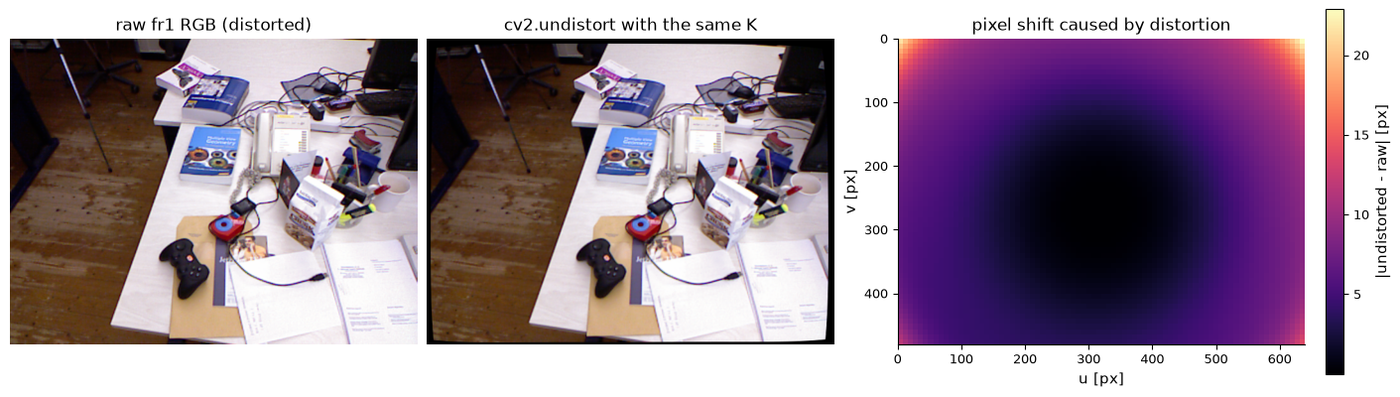

In [3]:
# --- How far does the fr1 lens distortion move each pixel? ---
# Undistort a grid of raw pixel positions and measure the shift; treating raw pixels as
# pinhole projections would bend every epipolar line and bias PnP near the borders.
u, v = np.meshgrid(np.arange(0, 640, 8), np.arange(0, 480, 8))
raw = np.column_stack([u.ravel(), v.ravel()]).astype(float)  # (N, 2) raw pixels
ideal = vo.undistort_pixels(raw, K, dist)  # (N, 2) ideal pinhole pixels, same K
shift = np.linalg.norm(ideal - raw, axis=1).reshape(u.shape)
centre = shift[(np.abs(v - 240) < 120) & (np.abs(u - 320) < 160)]
print(f"shift in the central half of the image: median {np.median(centre):.2f} px")
print(f"shift over the whole image: median {np.median(shift):.2f} px, max {shift.max():.1f} px")

# round trip: re-distort the undistorted pixels and compare with the raw input
rays = np.column_stack([(ideal - K[:2, 2]) / [K[0, 0], K[1, 1]], np.ones(len(ideal))])
back, _ = cv2.projectPoints(rays, np.zeros(3), np.zeros(3), K, dist)
default = cv2.undistortPoints(raw.reshape(-1, 1, 2), K, dist, P=K).reshape(-1, 2)
rays_d = np.column_stack([(default - K[:2, 2]) / [K[0, 0], K[1, 1]], np.ones(len(default))])
back_d, _ = cv2.projectPoints(rays_d, np.zeros(3), np.zeros(3), K, dist)
for label, b in [("default 5 iterations", back_d), ("20 iterations (vo.py)", back)]:
    print(f"round-trip error, {label}: max {np.abs(b.reshape(-1, 2) - raw).max():.4f} px")

img = seq.rgb(250)
und = cv2.undistort(img, K, dist)  # full-image remap, only for this visual comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
axes[0].imshow(img)
axes[0].set_title("raw fr1 RGB (distorted)")
axes[1].imshow(und)
axes[1].set_title("cv2.undistort with the same K")
im = axes[2].imshow(shift, extent=(0, 640, 480, 0), cmap="magma")
axes[2].set_title("pixel shift caused by distortion")
axes[2].set_xlabel("u [px]")
axes[2].set_ylabel("v [px]")
axes[2].grid(False)
fig.colorbar(im, ax=axes[2], label="|undistorted - raw| [px]")
for ax in axes[:2]:
    ax.axis("off")
viz.savefig(fig, PROJECT, "distortion")
plt.show()

## 3. Features and matches: ORB vs SIFT

* **ORB** = FAST corners on an 8-level image pyramid + a rotated 256-bit BRIEF descriptor.
  Binary descriptors are compared with the Hamming distance (popcount of an XOR), which is
  very fast. ORB is the front end of ORB-SLAM.
* **SIFT** = difference-of-Gaussians blobs + a 128-D histogram of gradient orientations
  (L2 distance). Slower, but more distinctive and better localised.

Each descriptor in image 1 is matched to its nearest neighbour in image 2. **Lowe's ratio
test** keeps a match only if it is clearly better than the second-best candidate,
$d_1 < r \cdot d_2$ ($r = 0.8$ for ORB, $0.75$ for SIFT): repetitive texture produces
ambiguous matches with $d_1 \approx d_2$, which are exactly the ones to drop.

In [4]:
# --- Detect and match ORB and SIFT features on a frame pair 10 frames apart ---
# Detection time is averaged over 20 frames (images read beforehand, so disk I/O is
# excluded); keypoints are undistorted right after detection.
def gray(k):
    return cv2.imread(str(seq.rgb_paths[k]), cv2.IMREAD_GRAYSCALE)


I, J = 100, 110  # noqa: E741 - frame pair used in sections 3-5 (0.34 s apart)
grays = [gray(k) for k in range(20)]
fronts = {"ORB": vo.FeatureFrontend("orb", 2000), "SIFT": vo.FeatureFrontend("sift", 2000)}
feats, rows = {}, []
for name, fe in fronts.items():
    fe.detect(grays[0])  # warm-up call (allocates the image pyramid)
    t0 = time.perf_counter()
    for g in grays:
        fe.detect(g)
    det_ms = 1000 * (time.perf_counter() - t0) / len(grays)
    feats[name] = {}
    for k in (I, J):
        uv_raw, desc = fe.detect(gray(k))
        feats[name][k] = (uv_raw, vo.undistort_pixels(uv_raw, K, dist), desc)
    t0 = time.perf_counter()
    m = fe.match(feats[name][I][2], feats[name][J][2])
    match_ms = 1000 * (time.perf_counter() - t0)
    rows.append({"features": name, "keypoints / image": len(feats[name][I][0]),
                 "detect [ms]": det_ms, "ratio-test matches": len(m),
                 "match [ms]": match_ms})  # fmt: skip
display(pd.DataFrame(rows).round(1))

,features,keypoints / image,detect [ms],ratio-test matches,match [ms]
0,ORB,2000,4.1,582,2.1
1,SIFT,1595,20.2,431,2.2


## 4. Monocular 2D-2D: the essential matrix

Write a matched pixel in normalised coordinates, $\hat{x} = K^{-1}(u, v, 1)^\top$. If camera 2
sees the world point $X_2 = R X_1 + t$, the two viewing rays and the baseline $t$ are
coplanar, which gives the **epipolar constraint**
$$\hat{x}_2^\top E\, \hat{x}_1 = 0, \qquad E = [t]_\times R .$$
$E$ has 5 degrees of freedom (3 rotation + 2 for the direction of $t$): multiplying $t$ by
any $s > 0$ leaves the constraint unchanged, so **a single moving camera cannot measure the
length of its translation**. Nister's **5-point solver** gives up to 10 candidate $E$ from 5
matches; inside **RANSAC** the candidate with the most inliers wins (inlier = Sampson
distance below 1 px). **MAGSAC++** replaces the hard inlier threshold by a
marginalisation over noise scales and adds local optimisation, which usually gives a more
accurate model.

$E$ decomposes into four $(R, \pm t)$ pairs; `cv2.recoverPose` triangulates the inliers and
keeps the pair that puts the points **in front of both cameras** (cheirality check).

In [5]:
# --- Estimate the relative pose of frames I -> J with RANSAC and MAGSAC++ ---
# T_gt = T_cJ,w @ T_w,cI maps points from camera I to camera J, the same convention as
# recoverPose's (R, t): X_J = R X_I + t.
fe = fronts["ORB"]
(uv1_raw, uv1, d1), (uv2_raw, uv2, d2) = feats["ORB"][I], feats["ORB"][J]
m = fe.match(d1, d2)
p1, p2 = uv1[m[:, 0]], uv2[m[:, 1]]  # (M, 2) undistorted pixels
T_gt = invert_T(seq.gt_poses[J]) @ seq.gt_poses[I]
gt_rot = rotation_error_deg(np.eye(3), T_gt[:3, :3])
print(
    f"GT motion I -> J: rotation {gt_rot:.2f} deg, translation {100 * np.linalg.norm(T_gt[:3, 3]):.1f} cm"
)

pair_rows = []
for method in ["ransac", "magsac"]:
    cv2.setRNGSeed(0)
    t0 = time.perf_counter()
    T_e, inl = vo.relative_pose_essential(p1, p2, K, method=method, threshold_px=1.0)
    ms = 1000 * (time.perf_counter() - t0)
    pair_rows.append(
        {
            "method": f"essential matrix, {method.upper()}",
            "inliers": f"{inl.sum()}/{len(m)}",
            "rotation err [deg]": rotation_error_deg(T_e[:3, :3], T_gt[:3, :3]),
            "t direction err [deg]": angle_between_deg(T_e[:3, 3], T_gt[:3, 3]),
            "|t| estimated [m]": np.linalg.norm(T_e[:3, 3]),
            "t error [cm]": np.nan,  # no scale -> no metric translation error
            "time [ms]": ms,
        }
    )
display(pd.DataFrame(pair_rows).round(3))

GT motion I -> J: rotation 4.30 deg, translation 13.9 cm


,method,inliers,rotation err [deg],t direction err [deg],|t| estimated [m],t error [cm],time [ms]
0,"essential matrix, RANSAC",415/582,0.643,1.772,1.0,NaN,6.656
1,"essential matrix, MAGSAC",446/582,0.588,2.428,1.0,NaN,3.620


The estimated $|t|$ is exactly 1: the essential matrix only knows the *direction* of travel.

To see the geometry, the left panel shows each match as a flow vector (green = MAGSAC++
inlier, red = outlier) and the right panel draws the **epipolar lines**
$l_2 = F \hat{x}_1$ (with $F = K^{-\top} E K^{-1}$) of a few inliers: each matched point in
image 2 must lie on the line induced by its partner in image 1. All lines meet in the
**epipole**, the image of the other camera centre.

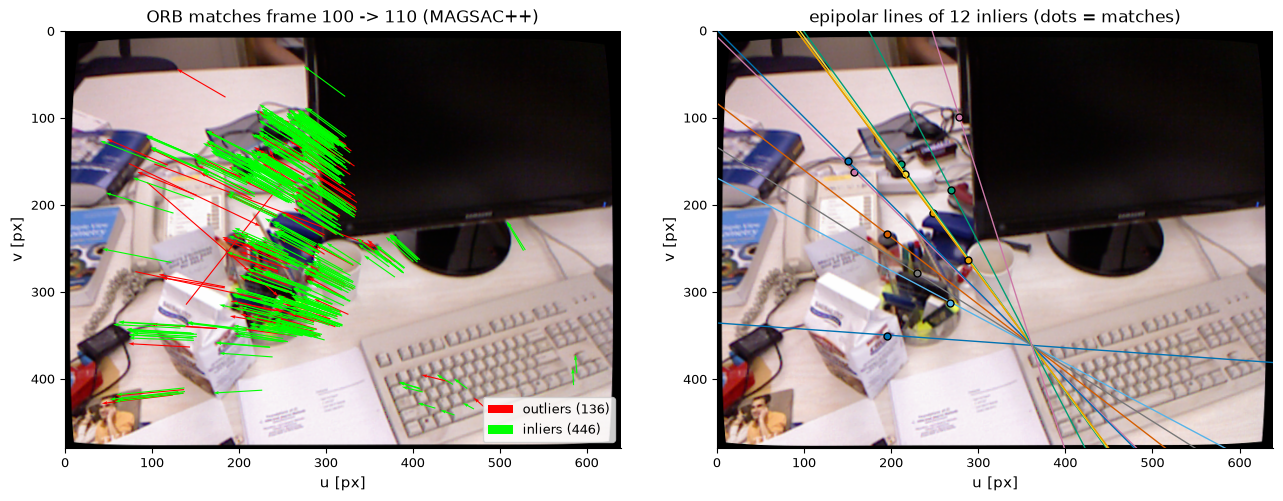

In [6]:
# --- Visualise inliers / outliers and epipolar lines on the undistorted image J ---
cv2.setRNGSeed(0)
T_e, inl = vo.relative_pose_essential(p1, p2, K, method="magsac")
F = fundamental_from_essential(essential_from_Rt(T_e[:3, :3], T_e[:3, 3]), K, K)
imgJ = cv2.undistort(seq.rgb(J), K, dist)  # undistorted image matches undistorted points

fig, axes = plt.subplots(1, 2, figsize=(13, 4.9))
axes[0].imshow(imgJ)
for ok, colour in [(False, "red"), (True, "lime")]:
    sel = inl == ok
    axes[0].quiver(p1[sel, 0], p1[sel, 1], (p2 - p1)[sel, 0], (p2 - p1)[sel, 1], color=colour,
                   angles="xy", scale_units="xy", scale=1, width=0.002,
                   label=f"{'inliers' if ok else 'outliers'} ({sel.sum()})")  # fmt: skip
axes[0].set_title(f"ORB matches frame {I} -> {J} (MAGSAC++)")
axes[0].legend(loc="lower right", frameon=True)
axes[1].imshow(imgJ)
rng = np.random.default_rng(1)
xs = np.array([0.0, 639.0])
for k, j in enumerate(rng.choice(np.flatnonzero(inl), 12, replace=False)):
    a, b, c = F @ np.array([*p1[j], 1.0])  # line a*u + b*v + c = 0 in image J
    colour = viz.color(k, unit=True)
    axes[1].plot(xs, -(a * xs + c) / b, color=colour, lw=1)
    axes[1].plot(*p2[j], "o", color=colour, ms=5, mec="k")
axes[1].set_xlim(0, 639)
axes[1].set_ylim(479, 0)
axes[1].set_title("epipolar lines of 12 inliers (dots = matches)")
for ax in axes:
    ax.set_xlabel("u [px]")
    ax.set_ylabel("v [px]")
    ax.grid(False)
viz.savefig(fig, PROJECT, "matches_epipolar")
plt.show()

## 5. RGB-D 3D-2D: depth + PnP gives metric motion

With a depth image the keypoints of frame I become 3D points in camera I:
$$X_I = z\, K^{-1} (u, v, 1)^\top ,$$
with $z$ read at the raw pixel and $(u, v)$ the undistorted pixel. Keypoints on depth
discontinuities (object borders) get a mix of foreground and background depth, so
`vo.depth_edge_mask` drops pixels whose 5x5 neighbourhood spans more than 5 % of the depth.

**Perspective-n-Point** finds the pose $(R, t)$ of camera J that best reprojects these
points onto their matches $x_J$:
$$\min_{R,t} \sum_i \rho\big(\lVert \pi(K (R X_{I,i} + t)) - x_{J,i} \rVert^2\big).$$
`cv2.solvePnPRansac` hypothesises poses from minimal samples (EPnP), keeps the one with the
most points under a 3 px reprojection error, and `cv2.solvePnPRefineLM` polishes it with
Levenberg-Marquardt on all inliers. The translation now has a metric scale, inherited from
the depth sensor.

In [7]:
# --- Metric pose of frame J from frame I's depth (same matches as above) ---
dI = seq.depth(I)
z = vo.lookup_depth(dI, uv1_raw, smooth_mask=vo.depth_edge_mask(dI))  # NaN = invalid
X1 = unproject(uv1, np.nan_to_num(z), K)  # (N, 3) points in camera I [m]
valid = np.isfinite(z)
mv = m[valid[m[:, 0]]]  # matches whose frame-I keypoint has a usable depth
print(f"{valid.mean():.0%} of the ORB keypoints in frame {I} have a valid, edge-free depth")
cv2.setRNGSeed(0)
t0 = time.perf_counter()
T_p, inl_p = vo.pose_pnp(X1[mv[:, 0]], uv2[mv[:, 1]], K, reproj_px=3.0)
ms = 1000 * (time.perf_counter() - t0)
pair_rows.append(
    {
        "method": "depth + PnP (EPnP-RANSAC + LM)",
        "inliers": f"{inl_p.sum()}/{len(mv)}",
        "rotation err [deg]": rotation_error_deg(T_p[:3, :3], T_gt[:3, :3]),
        "t direction err [deg]": angle_between_deg(T_p[:3, 3], T_gt[:3, 3]),
        "|t| estimated [m]": np.linalg.norm(T_p[:3, 3]),
        "t error [cm]": 100 * np.linalg.norm(T_p[:3, 3] - T_gt[:3, 3]),
        "time [ms]": ms,
    }
)
pair_rows.append({"method": "ground truth", "|t| estimated [m]": np.linalg.norm(T_gt[:3, 3])})
display(pd.DataFrame(pair_rows).round(3))

63% of the ORB keypoints in frame 100 have a valid, edge-free depth


,method,inliers,rotation err [deg],t direction err [deg],|t| estimated [m],t error [cm],time [ms]
0,"essential matrix, RANSAC",415/582,0.643,1.772,1.000,NaN,6.656
1,"essential matrix, MAGSAC",446/582,0.588,2.428,1.000,NaN,3.620
2,depth + PnP (EPnP-RANSAC + LM),271/327,0.683,2.917,0.137,0.751,0.929
3,ground truth,NaN,NaN,NaN,0.139,NaN,NaN


## 6. How much baseline does each method need?

The translation direction is only observable through **parallax**, the part of the image
motion caused by translation. Rotation moves all points alike; translation moves near points
more than far ones. With a small baseline the parallax drowns in keypoint noise and the
essential matrix is badly conditioned, while PnP only needs the 3D points to be correct.

Below, both estimators run on 12 start frames for frame gaps from 1 (33 ms) to 30 (1 s).
Too much baseline is also a problem: the views change more, so fewer descriptors pass the
ratio test.

,baseline [cm],GT rotation [deg],matches,E rot err [deg],E dir err [deg],PnP rot err [deg],PnP dir err [deg],PnP t err [cm]
gap,,,,,,,,
1,1.34,0.39,1332.0,0.37,43.27,0.27,17.25,0.39
2,2.49,0.77,1230.0,0.32,8.57,0.22,9.26,0.40
3,3.66,1.21,1147.0,0.38,9.56,0.45,9.91,0.61
5,6.30,1.56,892.0,0.83,12.49,0.41,7.24,0.81
8,10.17,3.00,675.0,0.77,2.69,0.53,3.88,0.78
12,15.11,4.05,511.0,1.38,9.89,0.82,4.02,1.28
20,23.00,6.91,266.5,0.95,2.43,0.76,2.19,1.15
30,28.09,10.54,184.5,5.51,55.45,1.00,3.33,1.55


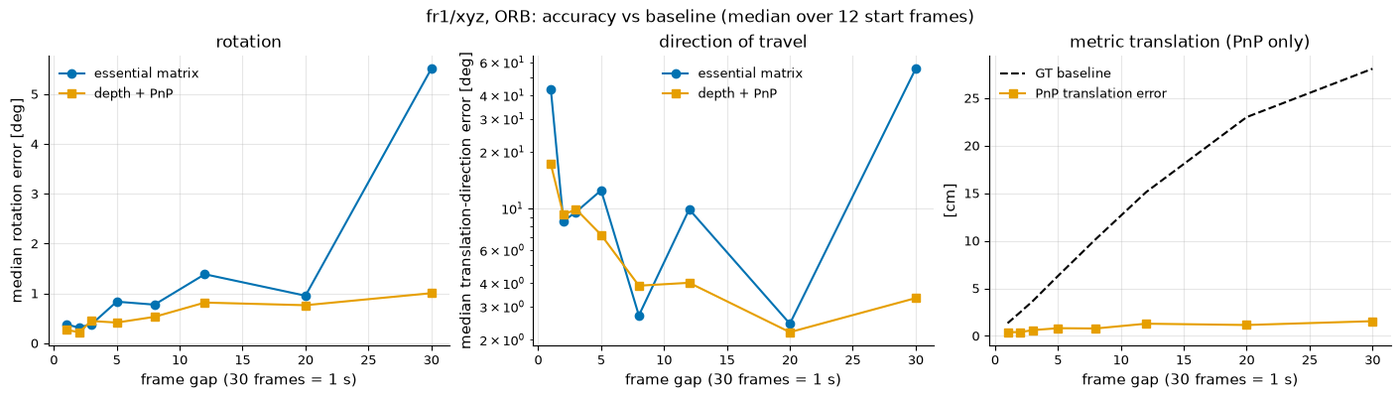

In [8]:
# --- Accuracy of E vs PnP as a function of the frame gap (baseline) ---
# Features are cached per frame: 12 start frames x 8 gaps = 96 frame pairs.
gaps = [1, 2, 3, 5, 8, 12, 20, 30]
starts = np.linspace(40, 700, 12).astype(int)
fe = fronts["ORB"]
cache = {}


def features(k):
    if k not in cache:
        uv_raw, desc = fe.detect(gray(k))
        cache[k] = (uv_raw, vo.undistort_pixels(uv_raw, K, dist), desc)
    return cache[k]


rows = []
for s0 in starts:
    uv_raw0, uv0, d0 = features(s0)
    dep = seq.depth(s0)
    z0 = vo.lookup_depth(dep, uv_raw0, smooth_mask=vo.depth_edge_mask(dep))
    X0 = unproject(uv0, np.nan_to_num(z0), K)
    for g in gaps:
        _, uvg, dg = features(s0 + g)
        mm = fe.match(d0, dg)
        Tg = invert_T(seq.gt_poses[s0 + g]) @ seq.gt_poses[s0]
        row = {"gap": g, "baseline [cm]": 100 * np.linalg.norm(Tg[:3, 3]),
               "GT rotation [deg]": rotation_error_deg(np.eye(3), Tg[:3, :3]),
               "matches": len(mm)}  # fmt: skip
        cv2.setRNGSeed(0)
        Te, _ = vo.relative_pose_essential(uv0[mm[:, 0]], uvg[mm[:, 1]], K)
        if Te is not None:
            row["E rot err [deg]"] = rotation_error_deg(Te[:3, :3], Tg[:3, :3])
            row["E dir err [deg]"] = angle_between_deg(Te[:3, 3], Tg[:3, 3])
        mv0 = mm[np.isfinite(z0[mm[:, 0]])]
        Tp, _ = vo.pose_pnp(X0[mv0[:, 0]], uvg[mv0[:, 1]], K)
        if Tp is not None:
            row["PnP rot err [deg]"] = rotation_error_deg(Tp[:3, :3], Tg[:3, :3])
            row["PnP dir err [deg]"] = angle_between_deg(Tp[:3, 3], Tg[:3, 3])
            row["PnP t err [cm]"] = 100 * np.linalg.norm(Tp[:3, 3] - Tg[:3, 3])
        rows.append(row)
sweep = pd.DataFrame(rows)
med = sweep.groupby("gap").median()
display(med.round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
axes[0].plot(med.index, med["E rot err [deg]"], "o-", label="essential matrix")
axes[0].plot(med.index, med["PnP rot err [deg]"], "s-", label="depth + PnP")
axes[0].set_ylabel("median rotation error [deg]")
axes[0].set_title("rotation")
axes[1].plot(med.index, med["E dir err [deg]"], "o-", label="essential matrix")
axes[1].plot(med.index, med["PnP dir err [deg]"], "s-", label="depth + PnP")
axes[1].set_yscale("log")
axes[1].set_ylabel("median translation-direction error [deg]")
axes[1].set_title("direction of travel")
axes[2].plot(med.index, med["baseline [cm]"], "k--", label="GT baseline")
axes[2].plot(med.index, med["PnP t err [cm]"], "s-", color=viz.color(1, unit=True),
             label="PnP translation error")  # fmt: skip
axes[2].set_ylabel("[cm]")
axes[2].set_title("metric translation (PnP only)")
for ax in axes:
    ax.set_xlabel("frame gap (30 frames = 1 s)")
    ax.legend()
fig.suptitle("fr1/xyz, ORB: accuracy vs baseline (median over 12 start frames)")
viz.savefig(fig, PROJECT, "baseline_sweep")
plt.show()

## 7. Chaining relative motions into a trajectory

A VO system composes one relative motion after another. If $T_{c_k r}$ maps points of the
reference frame $r$ into the current camera $c_k$, the new camera pose is
$$T_{w c_k} = T_{w r}\; T_{c_k r}^{-1}.$$
Every estimate carries a small error, and composition integrates these errors: the
trajectory **drifts**. Three pipelines run on all frames of fr1/xyz:

| pipeline | reference frame | scale |
|---|---|---|
| mono-E, oracle scale | last keyframe (new keyframe when the median parallax > 20 px) | step length copied from ground truth (**cheating**, isolates rotation + direction errors) |
| mono-E, unit scale | same | every step has length 1 (honest monocular VO) |
| RGB-D PnP, frame-to-frame | previous frame | metric, from the depth images |

The poses start at the first ground-truth pose so that all curves share the world frame.

In [9]:
# --- Run the three pipelines on all frames of fr1/xyz ---
# Each run returns a VOResult (frame ids, timestamps, Nx4x4 poses, per-frame log).
fe = vo.FeatureFrontend("orb", 2000)
pipelines = {
    "mono-E, oracle scale": (lambda: vo.run_mono_essential(seq, fe, scale="gt"), "se3"),
    "mono-E, unit scale": (lambda: vo.run_mono_essential(seq, fe, scale="unit"), "sim3"),
    "RGB-D PnP, frame-to-frame": (lambda: vo.run_pnp_vo(seq, fe, keyframes=False), "se3"),
}
runs, aligns = {}, {}
for name, (run, align) in pipelines.items():
    t0 = time.perf_counter()
    runs[name], aligns[name] = run(), align
    r = runs[name]
    print(f"{name:28s}: {len(r.frame_ids):4d} poses, {(r.log['status'] == 'kf').sum():4d} keyframes, "
          f"{r.ms_per_frame:5.1f} ms/frame, wall {time.perf_counter() - t0:5.1f} s")  # fmt: skip

mono-E, oracle scale        :  178 poses,  177 keyframes,   9.1 ms/frame, wall  12.1 s


mono-E, unit scale          :  178 poses,  177 keyframes,   7.8 ms/frame, wall  10.2 s


RGB-D PnP, frame-to-frame   :  790 poses,  790 keyframes,  10.2 ms/frame, wall  11.8 s


## 8. Evaluating a trajectory: alignment, ATE and RPE

The estimate lives in its own world frame (and, for monocular VO, its own scale), so it is
first **aligned** to the ground truth with the closed-form Umeyama method:
$$(s, R, t) = \arg\min \sum_i \lVert g_i - (s R p_i + t) \rVert^2 ,$$
with $s = 1$ (SE(3)) for metric pipelines and a free scale (Sim(3)) for monocular ones.

* **ATE** (absolute trajectory error) = RMSE of $\lVert g_i - (s R p_i + t)\rVert$: one
  number for global consistency, but dominated by when an error happened (an early rotation
  error swings the whole rest of the trajectory).
* **RPE** (relative pose error) over $\Delta$ = 1 s compares *motions*, not positions:
  $E_i = (Q_i^{-1} Q_{i+\Delta})^{-1} (P_i^{-1} P_{i+\Delta})$ for ground truth $Q$ and
  estimate $P$. Its translational RMSE is the **drift per second** - the natural metric for
  odometry.

The numbers are computed with `cvlab.metrics` and cross-checked against
[evo](https://github.com/MichaelGrupp/evo), the de-facto standard tool, once on the same
associated pose pairs and once fully independently from the TUM files (evo reads both files
and associates the timestamps itself, with a 10 ms tolerance).

In [10]:
# --- ATE / RPE for the three runs + cross-check against evo ---
from evo.core import metrics as evo_metrics
from evo.core import sync
from evo.tools import file_interface

viz.set_style()  # (re-)apply the repository style in case evo touched matplotlib settings
scores = {name: vo.evaluate(r, seq, align=aligns[name]) for name, r in runs.items()}
rows = []
for name, r in runs.items():
    gt = vo.gt_for(r, seq)
    ev = vo.evo_metrics(r.timestamps, r.poses, gt, align=aligns[name], delta_frames=1)
    own_rpe = vo.cvlab_frame_rpe(r.poses, gt, align_scale=scores[name]["scale"], delta=1)
    rows.append({"method": name, "align": aligns[name],
                 "ATE cvlab [m]": scores[name]["ate_rmse_m"], "ATE evo [m]": ev["ate_rmse_m"],
                 "RPE/pose cvlab [m]": own_rpe["trans_rmse"],
                 "RPE/pose evo [m]": ev["rpe_trans_rmse_m"]})  # fmt: skip
display(pd.DataFrame(rows).round(6))

# fully independent check: evo reads the TUM files and associates timestamps itself
name = "RGB-D PnP, frame-to-frame"
est_file = RUNS / "nb1_fr1_xyz_rgbd_f2f.txt"
runs[name].save_tum(est_file)
ref = file_interface.read_tum_trajectory_file(str(XYZ / "groundtruth.txt"))
est = file_interface.read_tum_trajectory_file(str(est_file))
ref, est = sync.associate_trajectories(ref, est, max_diff=0.01)
est.align(ref, correct_scale=False)
ape = evo_metrics.APE(evo_metrics.PoseRelation.translation_part)
ape.process_data((ref, est))
print(f"evo from files ({est.num_poses} associated poses): "
      f"ATE {ape.get_statistic(evo_metrics.StatisticsType.rmse):.6f} m "
      f"vs cvlab {scores[name]['ate_rmse_m']:.6f} m")  # fmt: skip

,method,align,ATE cvlab [m],ATE evo [m],RPE/pose cvlab [m],RPE/pose evo [m]
0,"mono-E, oracle scale",se3,0.064061,0.064061,0.015332,0.015332
1,"mono-E, unit scale",sim3,0.065193,0.065193,0.023575,0.023575
2,"RGB-D PnP, frame-to-frame",se3,0.048237,0.048237,0.005810,0.005810


evo from files (790 associated poses): ATE 0.048237 m vs cvlab 0.048237 m


## Results

**Trajectories.** Left: top view (mocap x-y plane, z is up) after alignment; right: each
coordinate over time. The oracle-scale and unit-scale monocular runs only have poses at
keyframes.

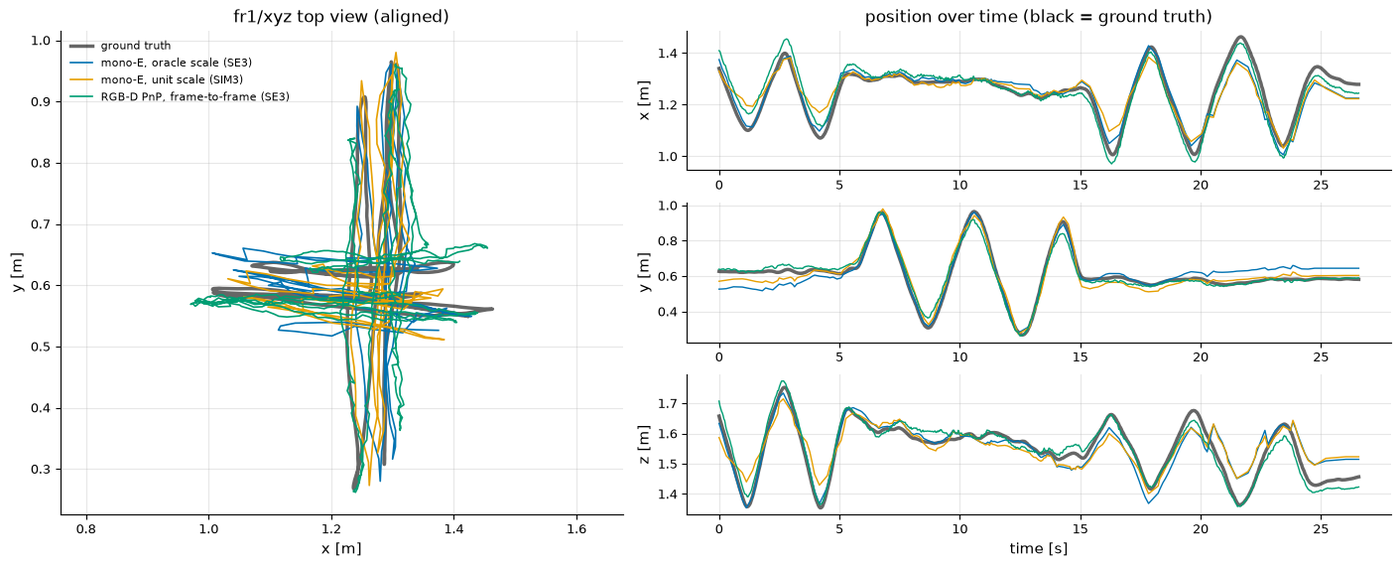

In [11]:
# --- Plot the aligned trajectories: top view and x / y / z over time ---
t_rel = seq.timestamps - seq.timestamps[0]
aligned = {name: vo.align_poses(r.poses, vo.gt_for(r, seq), aligns[name])[0]
           for name, r in runs.items()}  # fmt: skip
fig = plt.figure(figsize=(14, 5.6))
gs = fig.add_gridspec(3, 2, width_ratios=[1.0, 1.25])
ax = fig.add_subplot(gs[:, 0])
ax.plot(gt_xyz[:, 0], gt_xyz[:, 1], "k-", lw=2.5, alpha=0.6, label="ground truth")
for k, (name, P) in enumerate(aligned.items()):
    ax.plot(P[:, 0, 3], P[:, 1, 3], "-", lw=1.2, color=viz.color(k, unit=True),
            label=f"{name} ({aligns[name].upper()})")  # fmt: skip
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_aspect("equal", adjustable="datalim")
ax.set_title("fr1/xyz top view (aligned)")
ax.legend(loc="upper left", fontsize=8)
for d, lab in enumerate("xyz"):
    axd = fig.add_subplot(gs[d, 1])
    axd.plot(t_rel, gt_xyz[:, d], "k-", lw=2.5, alpha=0.6)
    for k, (name, P) in enumerate(aligned.items()):
        axd.plot(
            t_rel[runs[name].frame_ids], P[:, d, 3], "-", lw=1.0, color=viz.color(k, unit=True)
        )
    axd.set_ylabel(f"{lab} [m]")
    if d == 0:
        axd.set_title("position over time (black = ground truth)")
    if d == 2:
        axd.set_xlabel("time [s]")
viz.savefig(fig, PROJECT, "nb1_trajectories")
plt.show()

**Error over time.** The absolute position error after alignment shows *where* each pipeline
loses accuracy; the RPE over 1 s shows how fast it drifts locally.

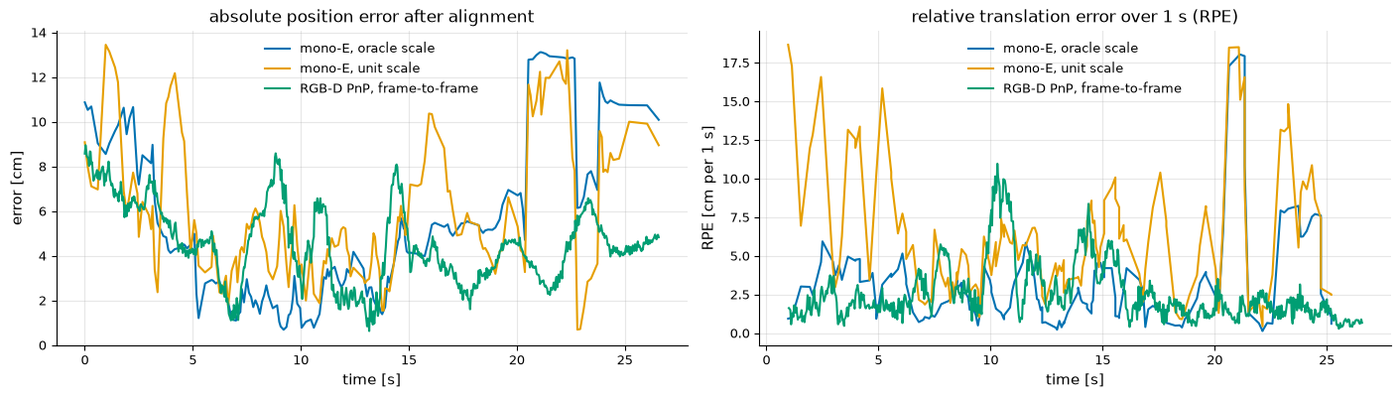

In [12]:
# --- Absolute (aligned) position error and 1-s RPE over time ---
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
for k, (name, P) in enumerate(aligned.items()):
    r = runs[name]
    err = np.linalg.norm(P[:, :3, 3] - vo.gt_for(r, seq)[:, :3, 3], axis=1)
    axes[0].plot(t_rel[r.frame_ids], 100 * err, color=viz.color(k, unit=True), label=name)
    rp = vo.rpe_time(r.timestamps, P, vo.gt_for(r, seq), delta_s=1.0)
    axes[1].plot(
        rp["t"] - seq.timestamps[0], 100 * rp["trans"], color=viz.color(k, unit=True), label=name
    )
axes[0].set_title("absolute position error after alignment")
axes[0].set_ylabel("error [cm]")
axes[1].set_title("relative translation error over 1 s (RPE)")
axes[1].set_ylabel("RPE [cm per 1 s]")
for ax in axes:
    ax.set_xlabel("time [s]")
    ax.legend()
viz.savefig(fig, PROJECT, "nb1_errors_over_time")
plt.show()

**Summary table** (measured on an Intel Core Ultra 9 275HX CPU; OpenCV uses all cores;
`ms/frame` excludes reading the PNG files). The table is also written to
`projects/12_visual_odometry/results/nb1_fr1_xyz.json`.

In [13]:
# --- Summary of the measured numbers (also saved as JSON for the README) ---
summary = pd.DataFrame([
    {"method": name, "alignment": aligns[name].upper(),
     "ATE RMSE [cm]": 100 * s["ate_rmse_m"], "ATE max [cm]": 100 * s["ate_max_m"],
     "RPE 1 s [cm]": 100 * s["rpe_trans_rmse_m"], "RPE 1 s [deg]": s["rpe_rot_rmse_deg"],
     "drift [% of distance]": s["drift_pct"], "poses": s["poses"],
     "keyframes": s["keyframes"], "ms/frame": s["ms_per_frame"]}
    for name, s in scores.items()
])  # fmt: skip
io.save_json({"sequence": "fr1_xyz", "frames": len(seq), "rows": summary.round(4).to_dict("records")},
             RESULTS / "nb1_fr1_xyz.json")  # fmt: skip
display(summary.round(2))

,method,alignment,ATE RMSE [cm],ATE max [cm],RPE 1 s [cm],RPE 1 s [deg],drift [% of distance],poses,keyframes,ms/frame
0,"mono-E, oracle scale",SE3,6.41,13.12,4.45,2.53,14.75,178,177,9.06
1,"mono-E, unit scale",SIM3,6.52,13.45,7.60,2.53,25.22,178,177,7.77
2,"RGB-D PnP, frame-to-frame",SE3,4.82,8.95,3.20,1.67,10.61,790,790,10.23


### Takeaways

* **Undistortion matters on fr1.** The lens moves pixels by 4.68 px on median and by up to
  22.9 px in the corners. Undistorting only the keypoints is cheap, and OpenCV's default
  5 iterations are not fully converged for these coefficients (up to 0.08 px round-trip
  error on our grid).
* **The essential matrix gives rotation and the direction of travel, never the distance.**
  On the 10-frame pair both RANSAC and MAGSAC++ recover the rotation to about 0.6 deg and
  the direction to about 2 deg, but $|t|$ is always 1. The baseline sweep shows the
  direction is useless at a 1-frame gap (median error 43 deg) and breaks down again at a
  30-frame gap (55 deg), where the camera has turned by about 10 deg and the median number
  of ratio-test matches has dropped from 1332 to 184.5. Monocular VO needs a baseline
  *sweet spot*, which is why it works on keyframes.
* **Depth + PnP gives metric motion** with a median translation error between 0.39 and
  1.55 cm across all gaps (0.75 cm for the 13.9 cm pair above), even where its *direction*
  error is large simply because the motion is tiny.
* **Monocular VO needs the scale from somewhere.** Copying each step length from ground
  truth (oracle) gives 6.41 cm ATE. Unit steps plus one Sim(3) scale give an almost equal
  ATE (6.52 cm) on fr1/xyz, because keyframes are triggered at a fixed 20 px parallax over a
  desk at nearly constant depth, so steps are similar in length. The local error shows the
  difference: the 1-s RPE grows from 4.45 to 7.60 cm. Notebook 02 shows this luck running
  out on fr1/desk.
* **RGB-D frame-to-frame PnP** is metric, tracks all 790 frames and has the lowest errors
  here (4.82 cm ATE, 3.20 cm RPE per second).
* `cvlab.metrics` and `evo` agree to the printed precision on the same pose pairs, and evo's
  own file association reproduces the ATE (0.048237 m).

The next notebook adds keyframes, a monocular map with triangulation, the harder fr1/desk
sequence and a look at failure cases.

## Exercises

Solutions: `projects/12_visual_odometry/solutions/` (run them from the repository root).

**Exercise 1 - RANSAC vs MAGSAC++.** For 50 frame pairs with a gap of 10 frames, estimate the
essential matrix with `method="ransac"` and `method="magsac"`. Compare the median rotation
error, translation-direction error and inlier ratio. Which is more accurate, and why?

In [14]:
# --- Exercise 1: RANSAC vs MAGSAC++ for the essential matrix ---
# TODO: loop over 50 start frames, match ORB features (fe.match), call
# vo.relative_pose_essential(p1, p2, K, method=...) for both methods and collect the errors
# against T_gt = invert_T(seq.gt_poses[j]) @ seq.gt_poses[i] in a DataFrame.

**Exercise 2 - What if we ignore the distortion?** Run `vo.run_pnp_vo(seq, fe, keyframes=False,
undistort=False)` and the essential-matrix baseline sweep with raw (distorted) keypoints. How do
ATE, RPE and the E-matrix errors change?

In [15]:
# --- Exercise 2: skip the undistortion ---
# TODO: run RGB-D frame-to-frame VO with undistort=True and undistort=False and compare
# vo.evaluate(...) for both; repeat the essential-matrix test of section 6 with raw pixels.

**Exercise 3 - Ratio-test threshold.** Sweep the ratio $r \in \{0.6, 0.7, 0.8, 0.9, 1.0\}$
for ORB on the pair (I, J) and over 50 pairs: how do the number of matches, the PnP inlier
ratio and the PnP translation error change?

In [16]:
# --- Exercise 3: sweep Lowe's ratio ---
# TODO: build vo.FeatureFrontend("orb", 2000, ratio=r) for each r, match, run vo.pose_pnp and
# record matches, inlier ratio and translation error against the ground truth.